# Model Training 1: Linear Regression

## 0. Setup

In [1]:
# imports
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import seaborn as sns
import joblib

In [4]:
# function for analyzing RMSE, MAE, and R² for different remaining lifetime ranges
def split_metrics_analysis(y_true, y_pred, threshold=2000):
    """
    Compute RMSE, MAE, and R² separately for low and high remaining lifetimes.
    
    Parameters:
    - y_true: true values (array-like or pandas Series)
    - y_pred: predicted values (array-like or pandas Series)
    - threshold: cutoff value for binning (default is 2000)
    
    Returns:
    - Dictionary with RMSE, MAE, and R² for below and above the threshold
    """
    
    # Ensure arrays
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()

    # Create masks
    mask_low = y_true <= threshold
    mask_high = y_true > threshold

    # Compute metrics for low remaining lifetimes
    rmse_low = np.sqrt(mean_squared_error(y_true[mask_low], y_pred[mask_low]))
    mae_low = mean_absolute_error(y_true[mask_low], y_pred[mask_low])
    r2_low = r2_score(y_true[mask_low], y_pred[mask_low])

    # Compute metrics for high remaining lifetimes
    rmse_high = np.sqrt(mean_squared_error(y_true[mask_high], y_pred[mask_high]))
    mae_high = mean_absolute_error(y_true[mask_high], y_pred[mask_high])
    r2_high = r2_score(y_true[mask_high], y_pred[mask_high])
    
    return {
        "RMSE_low": rmse_low, "MAE_low": mae_low, "R2_low": r2_low,
        "RMSE_high": rmse_high, "MAE_high": mae_high, "R2_high": r2_high
    }

In [5]:
# function to calculate evaluation metrics for thresholds
def calculate_threshold_metrics(y_test, y_pred):
    """
    Calculate evaluation metrics for thresholds of 1 year, 5 years, and 25 years.
    
    Parameters:
    - y_test: Ground truth values.
    - y_pred: Predicted values.
    
    Returns:
    - A pandas DataFrame containing the evaluation metrics for each threshold.
    """
    import pandas as pd

    thresholds = [365, 5 * 365, 25 * 365]
    results_dict = {
        "Metric": ["MAE Below", "RMSE Below", "R² Below", "MAE Above", "RMSE Above", "R² Above"]
    }

    for threshold in thresholds:
        results = split_metrics_analysis(y_test, y_pred, threshold=threshold)
        results_dict[f"Threshold {threshold} days"] = [
            results['MAE_low'],
            results['RMSE_low'],
            results['R2_low'],
            results['MAE_high'],
            results['RMSE_high'],
            results['R2_high']
        ]

    results_df = pd.DataFrame(results_dict)
    return results_df

In [6]:
# function to show scatter plot of true vs predicted values
def scatter_plot_evaluation(y_true, y_pred, xlabel="True Values (days)", ylabel="Predicted Values (days)"):
    """
    Visualize the evaluation of predictions against true values using a scatter plot.
    
    Parameters:
    - y_true: Ground truth values (array-like or pandas Series).
    - y_pred: Predicted values (array-like or pandas Series).
    - xlabel: Label for the x-axis (default is "True Values (days)").
    - ylabel: Label for the y-axis (default is "Predicted Values (days)").
    """
    plt.style.use('default')
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.3, color="blue")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.grid(True)
    plt.show()

In [7]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models using 1-year bins.
    
    Parameters:
        y_true (array-like): Ground truth values in days
        y_pred (array-like): Model predictions in days
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Define 1-year bin size in days
    bin_size = 365

    # Determine the range for each dataset
    max_residual = np.max(residuals)
    min_residual = np.min(residuals)
    max_value = max(np.max(y_true), np.max(y_pred))

    # Calculate number of bins
    bins_residuals = np.arange(min_residual, max_residual + bin_size, bin_size)
    bins_values = np.arange(0, max_value + bin_size, bin_size)

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))

    # 1. Residual Histogram
    sns.histplot(residuals, bins=bins_residuals, ax=axs[0, 0], color="C0", stat="count")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual (days)")
    axs[0, 0].set_ylabel("Density")
    axs[0, 0].grid(True)

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=bins_values, ax=axs[0, 1], color="C0", stat="count")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground Truth (days)")
    axs[0, 1].set_ylabel("Density")
    axs[0, 1].grid(True)

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=bins_values, ax=axs[1, 0], color="C0", stat="count")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction (days)")
    axs[1, 0].set_ylabel("Density")
    axs[1, 0].grid(True)

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=bins_values)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions")
    axs[1, 1].set_xlabel("Ground Truth (days)")
    axs[1, 1].set_ylabel("Prediction (days)")
    axs[1, 1].legend()
    axs[1, 1].grid(True)

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=bins_values)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual")
    axs[2, 0].set_xlabel("Prediction (days)")
    axs[2, 0].set_ylabel("Residual (days)")
    axs[2, 0].grid(True)

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=bins_values)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual")
    axs[2, 1].set_xlabel("Ground Truth (days)")
    axs[2, 1].set_ylabel("Residual (days)")
    axs[2, 1].grid(True)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## 1. Baseline Linear Regression for Lifetime

In [8]:
# read data
train_df = pd.read_csv("../Data/ModelInput/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/ModelInput/TestPreprocessed.csv")

In [9]:
# separate features and label
X_train1 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "NORAD_CAT_ID"])
y_train1 = train_df["LIFETIME"]

X_test1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "NORAD_CAT_ID"])
y_test1 = test_df["LIFETIME"]

In [10]:
# train linear regressor
model1 = LinearRegression()
model1.fit(X_train1, y_train1)

LinearRegression()

In [11]:
# predict
y_pred1 = model1.predict(X_test1)

In [12]:
# evaluate
print(f"Linear Regression Results:")
print(f"MAE: {mean_absolute_error(y_test1, y_pred1):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test1, y_pred1)):.2f}")
print(f"R² Score: {r2_score(y_test1, y_pred1):.2f}")

Linear Regression Results:
MAE: 460.87
RMSE: 910.90
R² Score: 0.96


In [13]:
# evaluate below and above thresholds of 1 year, 5 years, and 25 years
print(calculate_threshold_metrics(y_test1, y_pred1))

       Metric  Threshold 365 days  Threshold 1825 days  Threshold 9125 days
0   MAE Below          150.179632           226.484396           398.770711
1  RMSE Below          255.831847           407.660903           709.044390
2    R² Below           -8.261390             0.253674             0.924057
3   MAE Above          660.790548           797.568178           824.955312
4  RMSE Above         1149.582587          1335.268999          1657.376130
5    R² Above            0.945063             0.907693             0.515613


Linear Regression Model 1 - Scatter plot of true vs predicted values:


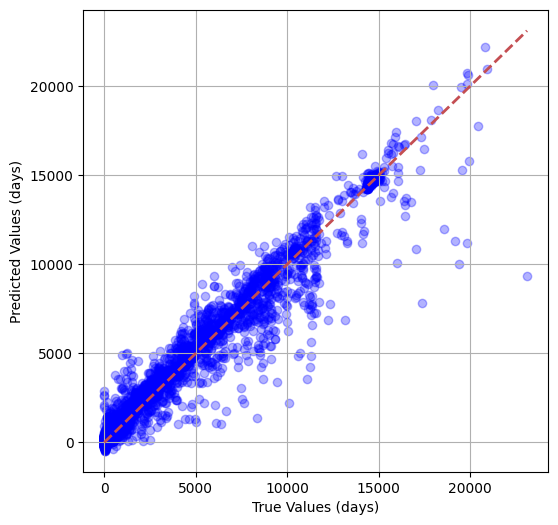

In [20]:
# show scatter plot
print("Linear Regression Model 1 - Scatter plot of true vs predicted values:")
scatter_plot_evaluation(y_test1, y_pred1)

Linear Regression Model 1 - Evaluation (Lifetime):


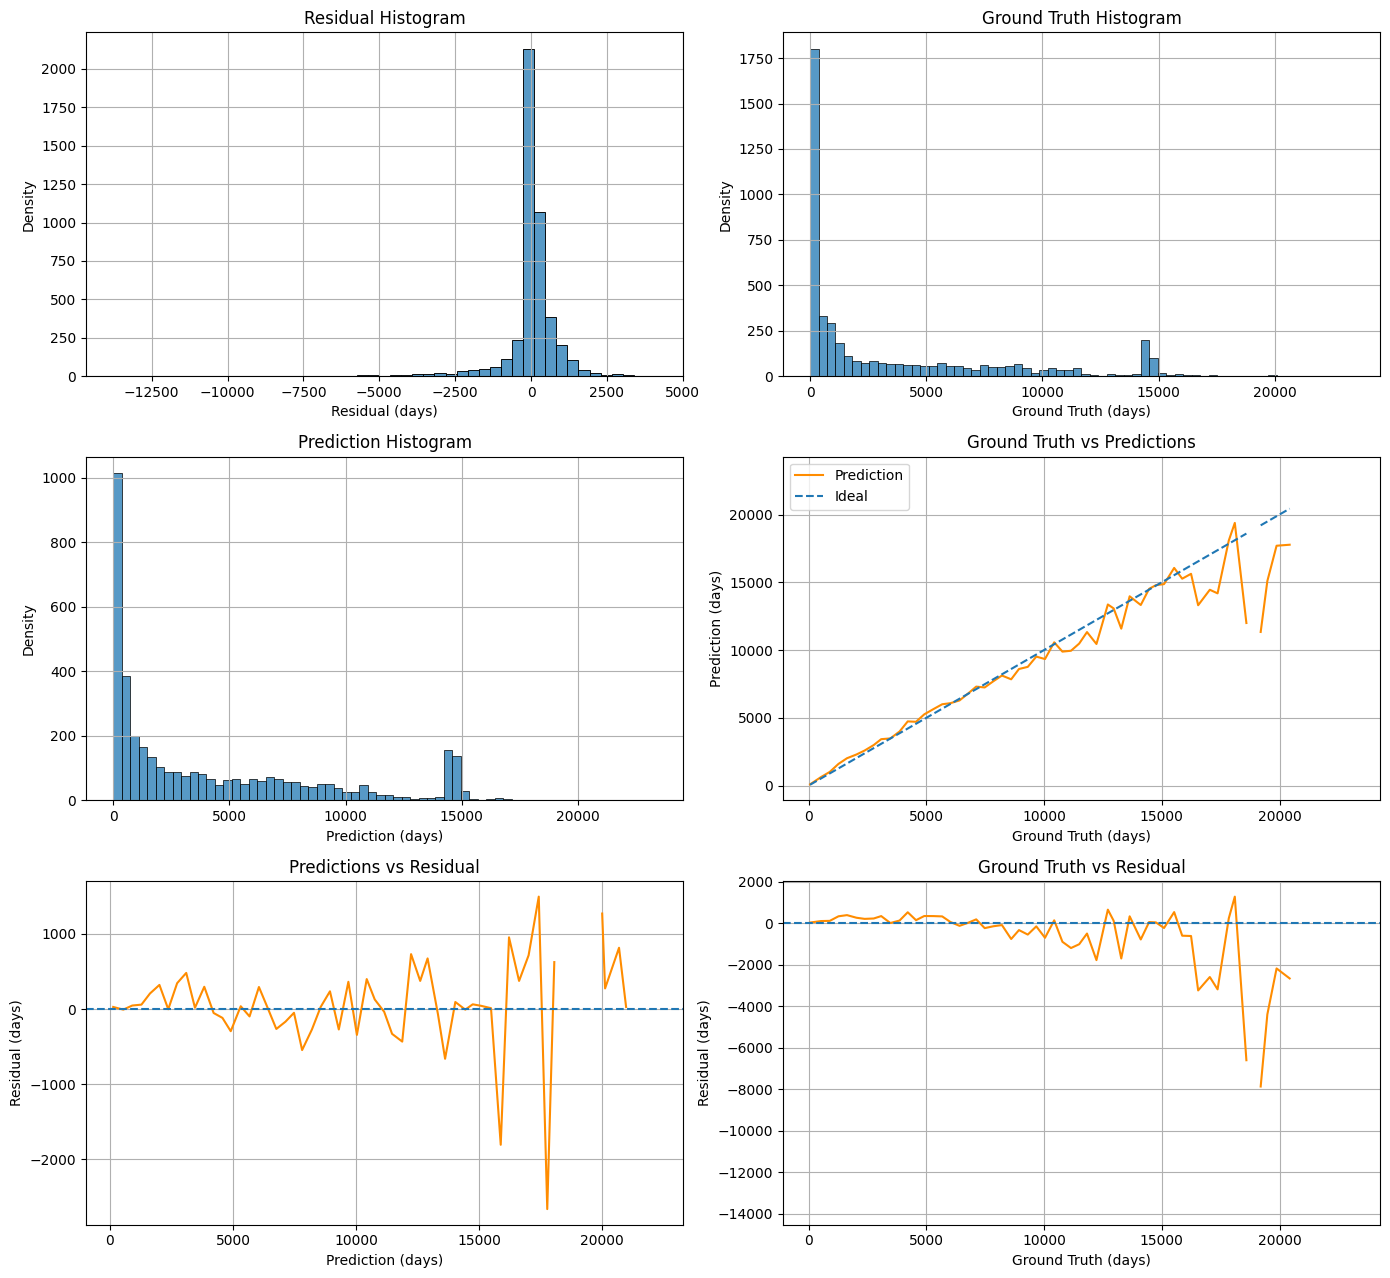

In [21]:
# plot model evaluation
print("Linear Regression Model 1 - Evaluation (Lifetime):")
plot_model_evaluation(y_test1, y_pred1) 

Residuals for below one year:


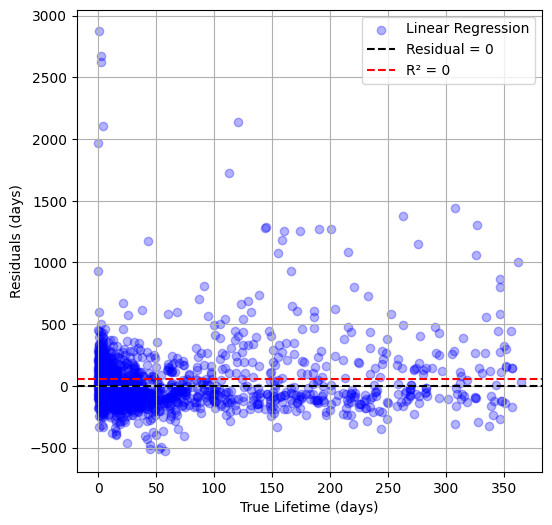

In [16]:
# plot residuals for below one year
print("Residuals for below one year:")
plt.figure(figsize=(6, 6))
plt.scatter(y_test1[y_test1 <= 365], y_pred1[y_test1 <= 365] - y_test1[y_test1 <= 365], alpha=0.3, label="Linear Regression", color="blue")
plt.xlabel("True Lifetime (days)")
plt.ylabel("Residuals (days)")
plt.axhline(0, color='black', linestyle='--', label="Residual = 0")
plt.axhline(y_test1[y_test1 <= 365].mean(), color='red', linestyle='--', label="R² = 0")
plt.legend()
plt.grid(True)
plt.show()

Model is really good at predicting the COSMOS 1408 Debris objects (Lifetime Peak in GT ), although the other Parameters should be confusing (since Launch date is not actually in 1982 but the ASAT test generated the debris in 2021)

In [17]:
# save model
joblib.dump(model1, "../Models/LinReg1.pkl")

['../Models/LinReg1.pkl']

## 2. Baseline Linear Regression for Remaining Lifetime

In [154]:
# separate features and label
X_train2 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "NORAD_CAT_ID"])
y_train2 = train_df["REMAINING_LIFETIME"]

X_test2 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "NORAD_CAT_ID"])
y_test2 = test_df["REMAINING_LIFETIME"]

In [155]:
# train linear regressor
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

LinearRegression()

In [156]:
# predict
y_pred2 = model2.predict(X_test2)

In [157]:
# evaluate
print(f"Linear Regression Results:")
print(f"MAE: {mean_absolute_error(y_test2, y_pred2):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test2, y_pred2)):.2f}")
print(f"R² Score: {r2_score(y_test2, y_pred2):.2f}")

Linear Regression Results:
MAE: 460.87
RMSE: 910.90
R² Score: 0.37


In [160]:
# evaluate below and above thresholds of 1 year, 5 years, and 25 years
print(calculate_threshold_metrics(y_test2, y_pred2))

       Metric  Threshold 365 days  Threshold 1825 days  Threshold 9125 days
0   MAE Below          253.627681           327.655391           449.133517
1  RMSE Below          444.924005           545.834412           841.778598
2    R² Below          -26.052506            -0.936938             0.383517
3   MAE Above         1010.450457          1876.786499          9457.324560
4  RMSE Above         1582.766080          2546.017083          9679.451534
5    R² Above            0.073622            -1.020203           -21.381248


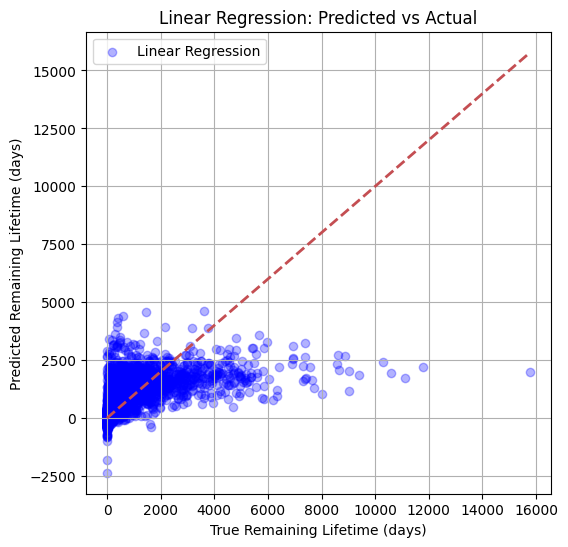

In [ ]:
# show scatter plot
scatter_plot_evaluation(y_test2, y_pred2)

Linear Regression Model 2 Evaluation (Remaining Lifetime)


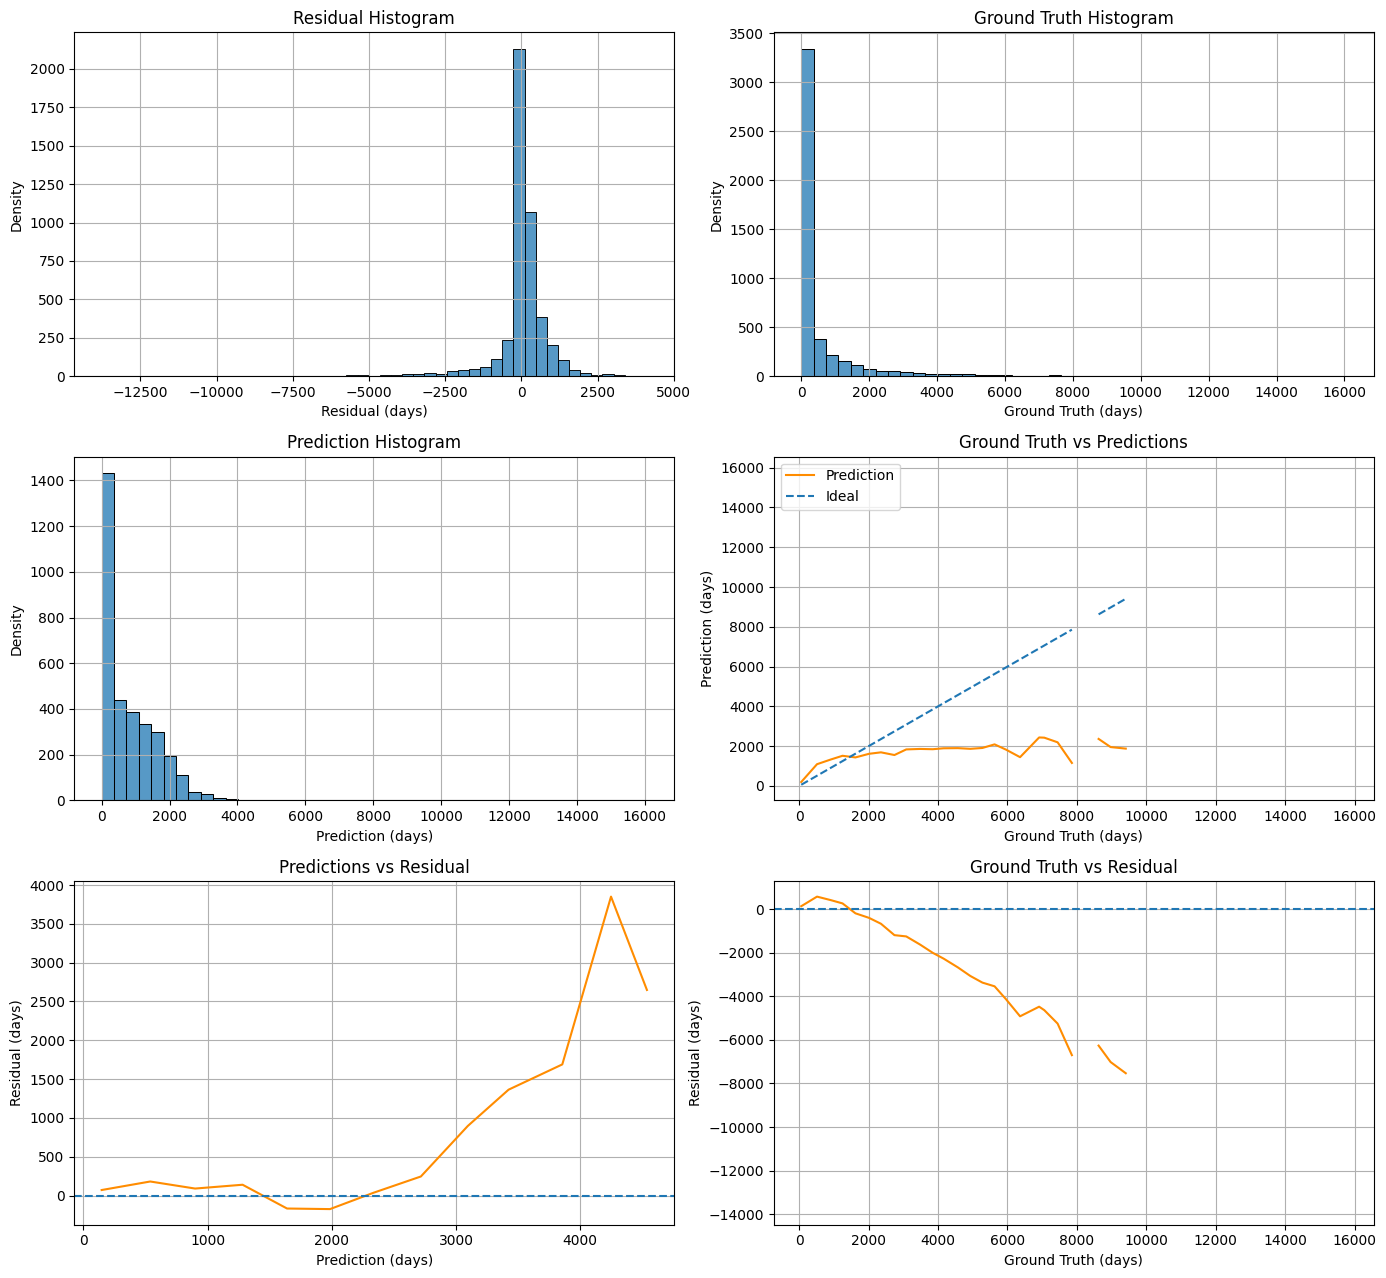

In [159]:
print("Linear Regression Model 2 Evaluation (Remaining Lifetime)")
plot_model_evaluation(y_test2, y_pred2)

In [161]:
# show highest predicted value
print(f"Highest predicted value: {y_pred2.max()} days")

Highest predicted value: 4632.47807737374 days


In [162]:
# show objects in test that have a longer remaining lifetime than 25 years
test_df[test_df['REMAINING_LIFETIME'] > 25 * 365]

,NORAD_CAT_ID,OBJECT_TYPE_DEBRIS,OBJECT_TYPE_ROCKET BODY,COUNTRY_CA,COUNTRY_CHBZ,COUNTRY_CIS,COUNTRY_ESA,COUNTRY_ESRO,COUNTRY_FR,COUNTRY_IND,...,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,LIFETIME,REMAINING_LIFETIME
952,4620,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.058396,-0.816916,0.623047,-0.144971,-0.269906,-0.009607,3.413128,3.477655,11097,9409
1389,7004,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.436607,1.265909,3.574738,-0.129823,-0.267779,-0.009607,2.261909,2.280941,17377,11767
2571,722,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.997340,1.154580,0.347486,-0.029968,-0.268410,-0.009607,3.649446,3.725922,19844,10577
3006,4861,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.010555,-1.236147,0.687142,-0.138285,-0.269804,-0.009607,1.721292,1.726252,19200,10291
3390,5358,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.029641,-0.713248,0.698550,-0.143536,-0.269839,-0.009607,1.042094,1.036223,19422,11108
4261,5808,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.630152,-1.071076,-0.521961,-0.139134,-0.269757,-0.009607,1.459753,1.459588,23115,15767


In [163]:
# save model
joblib.dump(model2, "../Models/LinReg2.pkl")

['../Models/LinReg2.pkl']

In [167]:
X_train1.columns

Index(['OBJECT_TYPE_DEBRIS', 'OBJECT_TYPE_ROCKET BODY', 'COUNTRY_CA',
       'COUNTRY_CHBZ', 'COUNTRY_CIS', 'COUNTRY_ESA', 'COUNTRY_ESRO',
       'COUNTRY_FR', 'COUNTRY_IND', 'COUNTRY_IRAN', 'COUNTRY_ISRA',
       'COUNTRY_ISS', 'COUNTRY_JPN', 'COUNTRY_NKOR', 'COUNTRY_ORB',
       'COUNTRY_PRC', 'COUNTRY_SKOR', 'COUNTRY_TWN', 'COUNTRY_UK',
       'COUNTRY_US', 'SITE_AFETR', 'SITE_AFWTR', 'SITE_CAS', 'SITE_ERAS',
       'SITE_FRGUI', 'SITE_HGSTR', 'SITE_JSC', 'SITE_KODAK', 'SITE_KSCUT',
       'SITE_KYMTR', 'SITE_NSC', 'SITE_OREN', 'SITE_PKMTR', 'SITE_RLLC',
       'SITE_SADOL', 'SITE_SCSLA', 'SITE_SEM', 'SITE_SMTS', 'SITE_SNMLP',
       'SITE_SRI', 'SITE_SVOB', 'SITE_TNSTA', 'SITE_TSC', 'SITE_TTMTR',
       'SITE_VOSTO', 'SITE_WLPIS', 'SITE_WOMRA', 'SITE_WRAS', 'SITE_WSC',
       'SITE_XSC', 'SITE_YAVNE', 'SITE_YSLA', 'SITE_YUN', 'LAUNCH_YEAR',
       'LAUNCH_MONTH', 'EPOCH_YEAR', 'EPOCH_MONTH', 'DAYS_SINCE_LAUNCH',
       'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION',
  